![第二章封面](../../assets/images/chapter-02-cover.jpg)

# 《零基础学习量化金融》
## 从Python到AI量化交易实战 第一期
### 第二章：你的第一个量化实验

---

## 本章你将学会

- ✅ 股票数据 **OHLCV** 长什么样
- ✅ 什么是 **收益率**（先举 100→110 的例子，再写公式）
- ✅ 用 **pandas** 计算日收益率
- ✅ 画 **收益率曲线** 和 **Histogram**
- ✅ 第一次做 **三只股票波动对比** 小实验

**当前等级**  
🎮 **Lv.1 量化探索者**（数据分析模块）

**本章难度**  
⭐⭐☆☆☆

**预计学习时间**  
30～45 分钟（需联网）

**前置知识**

- 完成 **第一章**（或具备量化金融基本概念）
- Python 基础、会用 Jupyter

---

从这一章开始，我们真正进入 **「数据分析」** —— 节奏依然零基础，不追求讲全，只追求 **你能亲手跑出结果**。

> 提示：学完记得做文末 **🎯 挑战任务**，换 Tesla / 英伟达练一遍，参与感越强，记得越牢。

### 本地挑战复现

三选一选择 COIN，使用缓存真实历史行情完成波动和 Histogram。

标的：COIN（Coinbase）；数据：AkShare 新浪美股前复权缓存，最新日期 2026-11-04
有效日收益样本：1397；日波动（样本标准差）：5.317%


C:\Users\yangx\AppData\Local\Temp\ipykernel_21892\2011091777.py:9: UserWarning: Glyph 26085 (\N{CJK UNIFIED IDEOGRAPH-65E5}) missing from font(s) DejaVu Sans.
  fig, ax = plt.subplots(figsize=(8,4)); ax.hist(challenge_returns, bins=40, color='steelblue', edgecolor='white'); ax.axvline(0,color='black',linestyle='--'); ax.set(title='COIN 日收益率 Histogram（挑战）',xlabel='日收益率',ylabel='天数'); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
C:\Users\yangx\AppData\Local\Temp\ipykernel_21892\2011091777.py:9: UserWarning: Glyph 25910 (\N{CJK UNIFIED IDEOGRAPH-6536}) missing from font(s) DejaVu Sans.
  fig, ax = plt.subplots(figsize=(8,4)); ax.hist(challenge_returns, bins=40, color='steelblue', edgecolor='white'); ax.axvline(0,color='black',linestyle='--'); ax.set(title='COIN 日收益率 Histogram（挑战）',xlabel='日收益率',ylabel='天数'); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
C:\Users\yangx\AppData\Local\Temp\ipykernel_21892\2011091777.py:9: UserWarning: Glyph 30410 (\N{CJK UNIFIED IDEOGRAPH-76CA}) m

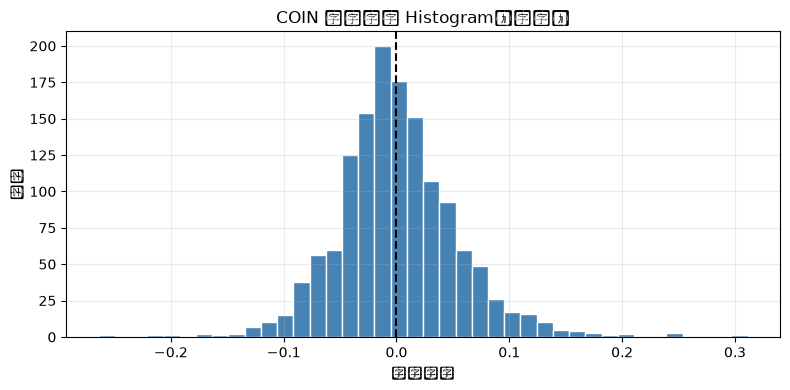

思考：长尾表示少数交易日出现远离常态的大涨跌，提示极端风险可能高于正态分布直觉。


In [1]:
# 第二章挑战：COIN 波动与收益率分布（真实 AkShare 缓存）
import pandas as pd
import matplotlib.pyplot as plt
challenge_price = pd.read_csv('../../data/akshare_us/COIN.csv', parse_dates=['date']).set_index('date')['close'].dropna()
challenge_returns = challenge_price.pct_change().dropna()
challenge_vol = challenge_returns.std()
print(f'标的：COIN（Coinbase）；数据：AkShare 新浪美股前复权缓存，最新日期 {challenge_price.index.max().date()}')
print(f'有效日收益样本：{len(challenge_returns)}；日波动（样本标准差）：{challenge_vol:.3%}')
fig, ax = plt.subplots(figsize=(8,4)); ax.hist(challenge_returns, bins=40, color='steelblue', edgecolor='white'); ax.axvline(0,color='black',linestyle='--'); ax.set(title='COIN 日收益率 Histogram（挑战）',xlabel='日收益率',ylabel='天数'); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
print('思考：长尾表示少数交易日出现远离常态的大涨跌，提示极端风险可能高于正态分布直觉。')

### 挑战思考
Histogram 长尾提示少数极端涨跌较大；标准差总结整体离散程度，但不单独刻画尾部风险。截图任务已通过 Notebook 保存的 Histogram 图输出完成。

> 本地复现数据说明：Yahoo Finance 对本环境限流。以下行情来自 AkShare 新浪财经接口，已保存为真实历史日线缓存，采用接口返回的前复权价格。指标公式与教材一致；数据源和复权处理可能导致数值与教材历史输出不同。

### 环境准备

运行下面这个代码块一次即可。如果提示缺少库，在项目根目录执行：`pip install -r requirements.txt`

In [2]:
# ========== 环境准备：导入库并设置画图中文 ==========
import warnings                          # 导入警告控制模块
warnings.filterwarnings('ignore')  # 忽略次要警告，输出更干净

import numpy as np           # 数值计算
import pandas as pd          # 表格数据处理
import matplotlib.pyplot as plt  # 绘图
import akshare as ak        # Yahoo 限流后使用 AkShare 新浪财经美股历史数据

plt.rcParams['font.sans-serif'] = ['SimHei']  # Windows 黑体；Mac 可改 PingFang SC
plt.rcParams['axes.unicode_minus'] = False     # 负号正常显示

print('环境就绪 ✓')                       # 提示：环境加载完成


环境就绪 ✓


---

### 2.1 股票数据介绍

在量化里，我们最常打交道的是 **日线行情表**。每一行 = 一个交易日，每一列 = 当天市场记录下来的一个数字。

下面五列几乎无处不在（英文列名，全球通用）：

| 列名 | 英文 | 含义（直觉版） |
|------|------|----------------|
| **开盘** | Open | 当天第一笔成交价 |
| **最高** | High | 当天成交过的最高价 |
| **最低** | Low | 当天成交过的最低价 |
| **收盘** | Close | 当天最后一笔成交价（最常用） |
| **成交量** | Volume | 当天一共成交了多少股 |

**为什么最常用收盘价？** 因为收盘代表这一天「最终定价」，研究涨跌、算收益率，默认都用 Close。

接下来我们用 **苹果（AAPL）** 的真实数据看一眼。

In [3]:
# ========== 下载苹果 AAPL 最近约 1 年的日线数据 ==========
# AkShare 新浪财经真实历史数据缓存；字段统一为教材使用的 OHLCV 名称
aapl = pd.read_csv('../../data/akshare_us/AAPL.csv', parse_dates=['date']).set_index('date')
aapl = aapl.rename(columns={'open':'Open','high':'High','low':'Low','close':'Close','volume':'Volume'}).dropna()

print('数据形状（行=交易日，列=字段）：', aapl.shape)  # 例如 (251, 5)
print('\n前 5 行：')  # 提示下方表格
display(aapl.head())  # Jupyter 里美观显示表格前几行

print('\n各列含义速查：')  # 打印列名说明
for col in aapl.columns:  # 遍历每一列的名字
    print(f'  {col}')  # 格式化打印


数据形状（行=交易日，列=字段）： (10068, 5)

前 5 行：


,Open,High,Low,Close,Volume
date,,,,,
1984-09-07,-10.4853,-10.4836,-10.4864,-10.4853,2981600.0
1984-09-10,-10.4853,-10.4847,-10.4881,-10.4858,2346400.0
1984-09-11,-10.4847,-10.4814,-10.4847,-10.4836,5444000.0
1984-09-12,-10.4836,-10.4830,-10.4870,-10.4870,4773600.0
1984-09-13,-10.4808,-10.4803,-10.4808,-10.4808,7429600.0



各列含义速查：
  Open
  High
  Low
  Close
  Volume


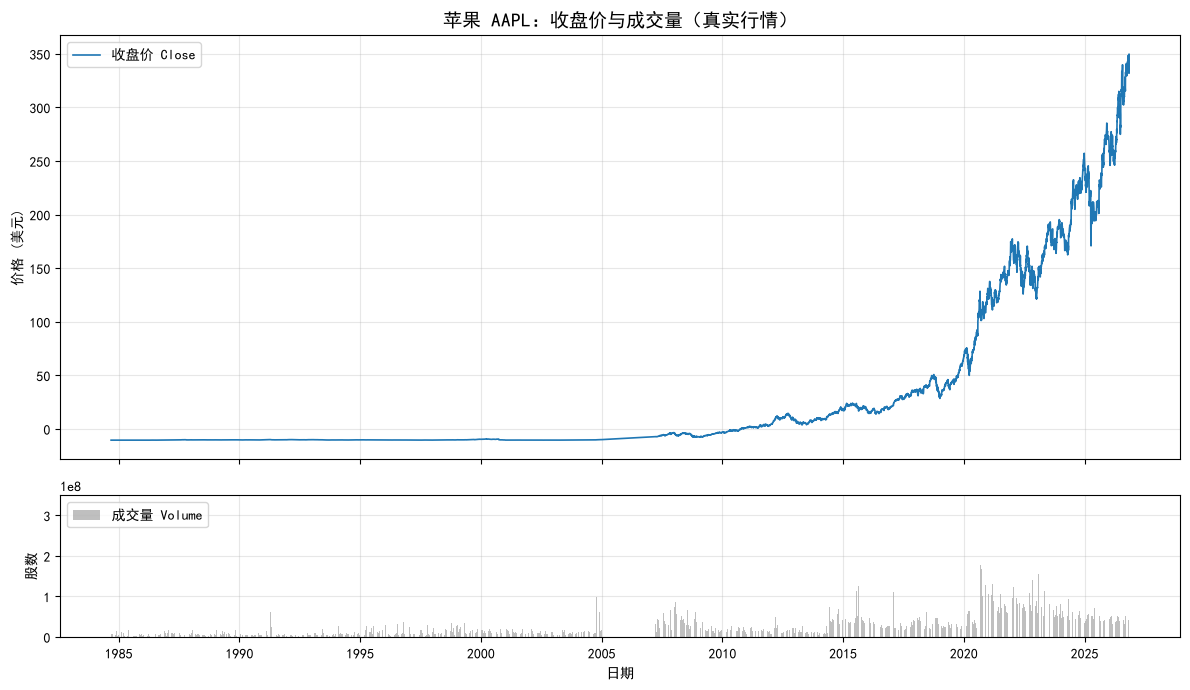

In [4]:
# ========== 配图1：收盘价折线 + 成交量柱状图 ==========
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,  # 2行1列，共用日期横轴
                         gridspec_kw={'height_ratios': [3, 1]})  # 上图更高

axes[0].plot(aapl.index, aapl['Close'], color='tab:blue', linewidth=1.2, label='收盘价 Close')  # 上图：画折线
axes[0].set_ylabel('价格 (美元)')  # 设置上图纵轴
axes[0].set_title('苹果 AAPL：收盘价与成交量（真实行情）', fontsize=14)  # 设置上图标题
axes[0].legend(loc='upper left')  # 显示上图图例
axes[0].grid(True, alpha=0.3)  # 上图显示网格

axes[1].bar(aapl.index, aapl['Volume'], width=0.8, color='gray', alpha=0.5, label='成交量 Volume')  # 下图：画柱状图
axes[1].set_ylabel('股数')  # 设置下图纵轴
axes[1].legend(loc='upper left')  # 显示下图图例
axes[1].set_xlabel('日期')  # 设置下图横轴（日期）
axes[1].grid(True, alpha=0.3)  # 下图显示网格

plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


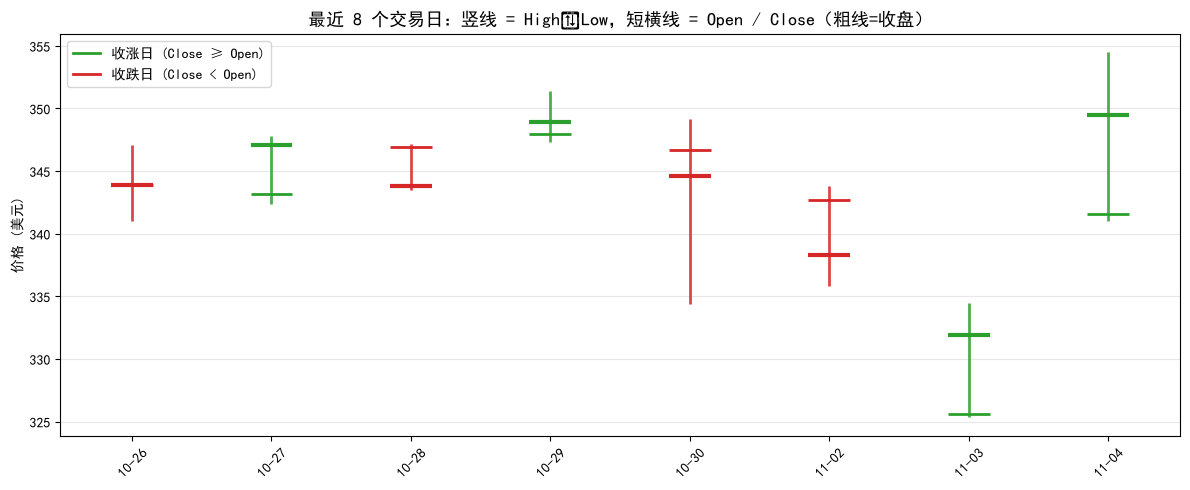

小贴士：一天之内，价格一定满足  Low ≤ Open, Close ≤ High


In [5]:
# ========== 配图2：最近8天 OHLC 示意图 ==========
sample = aapl.tail(8).copy()   # 取最后 8 个交易日
dates = range(len(sample))     # 0,1,...,7 用作横轴位置

fig, ax = plt.subplots(figsize=(12, 5))  # 创建子图

for i, (idx, row) in enumerate(sample.iterrows()):  # 逐行遍历每一天
    o, h, l, c = row['Open'], row['High'], row['Low'], row['Close']  # 开高低收
    color = 'tab:red' if c < o else 'tab:green'   # 收跌红色、收涨绿色
    ax.vlines(i, l, h, color=color, linewidth=2, alpha=0.85)   # 竖线：最低到最高
    ax.hlines(o, i - 0.15, i + 0.15, color=color, linewidth=2)  # 开盘价短横线
    ax.hlines(c, i - 0.15, i + 0.15, color=color, linewidth=3)  # 收盘价粗横线

ax.set_xticks(dates)  # 设置横轴刻度位置
ax.set_xticklabels([d.strftime('%m-%d') for d in sample.index], rotation=45)  # 日期标签
ax.set_ylabel('价格 (美元)')  # 设置子图纵轴
ax.set_title('最近 8 个交易日：竖线 = High↔Low，短横线 = Open / Close（粗线=收盘）', fontsize=13)  # 设置子图标题
ax.grid(True, axis='y', alpha=0.3)  # 显示网格

from matplotlib.lines import Line2D  # 自定义图例用的小线段
legend_elements = [  # 自定义图例项
    Line2D([0], [0], color='tab:green', linewidth=2, label='收涨日 (Close ≥ Open)'),  # 线宽
    Line2D([0], [0], color='tab:red', linewidth=2, label='收跌日 (Close < Open)'),  # 线宽
]                                              # 数组拼接结束
ax.legend(handles=legend_elements, loc='upper left')  # 显示图例
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片

print('小贴士：一天之内，价格一定满足  Low ≤ Open, Close ≤ High')  # 打印小贴士


---

### 2.2 什么是收益率（本章重点）

投资里，我们很少只说「涨了 5 块钱」，更关心 **相对自己本金涨了多少**——这就是 **收益率**。

#### 先用生活例子（不要急着背公式）

假设你 **100 元** 买了一只股票：

- 过几天价格变成 **110 元** → 赚了 **10 元**
- 相对本金：10 ÷ 100 = **10%** → 我们说收益率是 **+10%**

反过来：

- 100 元跌到 **90 元** → 亏了 10 元
- 收益率 = -10 ÷ 100 = **-10%**

所以：**涨跌 = 价格变化；收益率 = 价格变化占昨天价格的比例**。

#### 再写公式（和上面的例子是一回事）

设昨天收盘价为 $P_{t-1}$，今天收盘价为 $P_t$，**日收益率** 定义为：

$$
r_t = \frac{P_t - P_{t-1}}{P_{t-1}}
$$

代入例子：$P_{t-1}=100,\; P_t=110$ → $r_t = (110-100)/100 = 0.10 = 10\%$

> **记忆口诀**：今天比昨天 **多出来的比例**，就是收益率。

In [6]:
# ========== 验证 100元→110元 的收益率例子 ==========
p_yesterday, p_today = 100, 110   # 昨天价、今天价
r = (p_today - p_yesterday) / p_yesterday  # 收益率公式
print(f'昨天: {p_yesterday} 元, 今天: {p_today} 元')  # 格式化打印
print(f'日收益率 r = {r:.2%}')  # :.2% 表示格式化为百分比，保留2位小数


昨天: 100 元, 今天: 110 元
日收益率 r = 10.00%


---

### 2.3 日收益率计算

对一整列收盘价，我们不必每天手写公式。pandas 一行就能算 **相邻两天的收益率**：

```python
df['日收益率'] = df['Close'].pct_change()
```

`pct_change()` 做的正是 $r_t = (P_t - P_{t-1}) / P_{t-1}$。第一行没有「昨天」，所以是空值（NaN），这很正常。

In [7]:
# ========== 用 pandas 计算整列日收益率 ==========
df = aapl[['Close']].copy()              # 只保留收盘价一列
df['日收益率'] = df['Close'].pct_change()  # 今天相对昨天的涨跌比例

print('最近 10 天的收盘价与日收益率：')  # 打印输出
display(df.tail(10))  # 在 Notebook 中美观显示表格

# 手算最后一天，和 pct_change 对照
row_today = df.iloc[-1]       # 最后一行（今天）
row_yesterday = df.iloc[-2]   # 倒数第二行（昨天）
manual_r = (row_today['Close'] - row_yesterday['Close']) / row_yesterday['Close']  # 手算收益率用于验证
print(f"\n验证最后一天：手算 {manual_r:.4%}，pct_change {row_today['日收益率']:.4%}")  # 对照手算与 pandas 结果


最近 10 天的收盘价与日收益率：


,Close,日收益率
date,,
2026-10-22,348.220,0.012297
2026-10-23,347.725,-0.001422
2026-10-26,343.910,-0.010971
2026-10-27,347.100,0.009276
2026-10-28,343.830,-0.009421
2026-10-29,348.910,0.014775
2026-10-30,344.630,-0.012267
2026-11-02,338.320,-0.018309
2026-11-03,331.900,-0.018976



验证最后一天：手算 5.3058%，pct_change 5.3058%


---

### 2.4 可视化收益率

数字表格不够直观。金融数据分析里，我们常用两类图建立「手感」：

1. **日收益率曲线** —— 每天涨跌幅度一目了然  
2. **直方图（Histogram）** —— 大部分日子涨跌集中在哪个区间？有没有「极端大涨跌」？

下面仍以苹果为例。

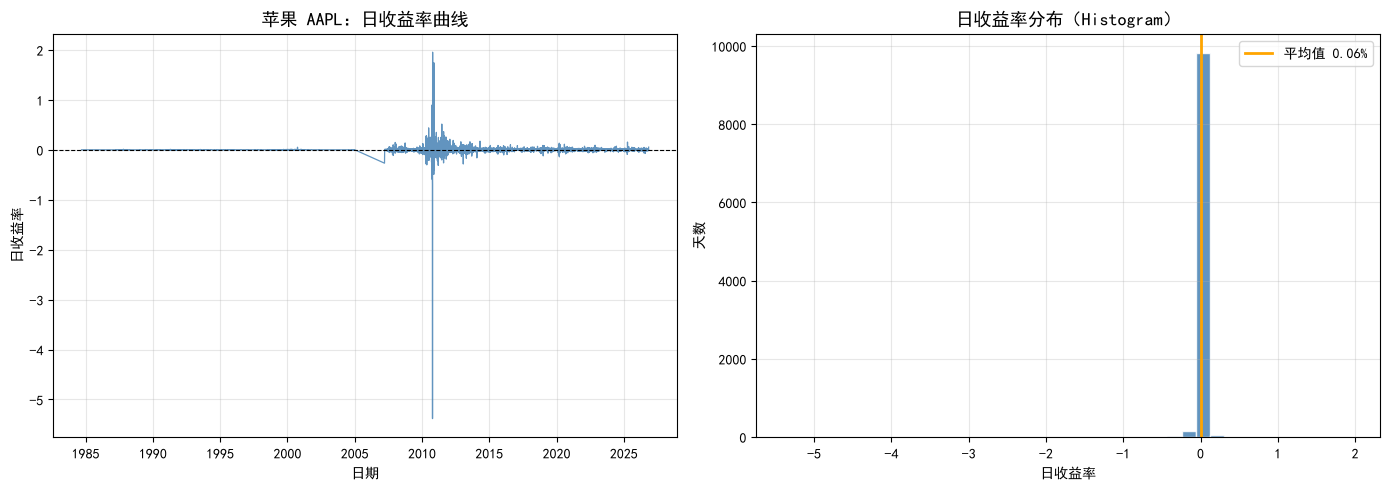

样本天数: 10067
平均日收益率: 0.056%（正=整体偏多涨）
日收益率标准差: 7.055%（越大=波动越剧烈）


In [8]:
# ========== 日收益率曲线 + 直方图 ==========
rets = df['日收益率'].dropna()  # 去掉第一天的 NaN

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # 1行2列

axes[0].plot(rets.index, rets.values, color='steelblue', linewidth=0.9, alpha=0.85)  # 上图：画折线
axes[0].axhline(0, color='black', linewidth=0.8, linestyle='--')  # 零轴参考线
axes[0].set_title('苹果 AAPL：日收益率曲线', fontsize=13)  # 设置上图标题
axes[0].set_xlabel('日期')  # 执行本行代码
axes[0].set_ylabel('日收益率')  # 设置上图纵轴
axes[0].grid(True, alpha=0.3)  # 上图显示网格

axes[1].hist(rets.values, bins=40, color='steelblue', edgecolor='white', alpha=0.85)  # 画直方图
axes[1].axvline(0, color='black', linewidth=0.8, linestyle='--')  # 中图画垂直参考线
axes[1].axvline(rets.mean(), color='orange', linewidth=2, label=f'平均值 {rets.mean():.2%}')  # 求平均值
axes[1].set_title('日收益率分布（Histogram）', fontsize=13)  # 设置下图标题
axes[1].set_xlabel('日收益率')  # 设置下图横轴（日期）
axes[1].set_ylabel('天数')  # 设置下图纵轴
axes[1].legend()                                    # 显示下图图例
axes[1].grid(True, alpha=0.3)  # 下图显示网格

plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片

print(f'样本天数: {len(rets)}')  # 打印统计结果
print(f'平均日收益率: {rets.mean():.3%}（正=整体偏多涨）')  # 格式化打印
print(f'日收益率标准差: {rets.std():.3%}（越大=波动越剧烈）')  # 格式化打印


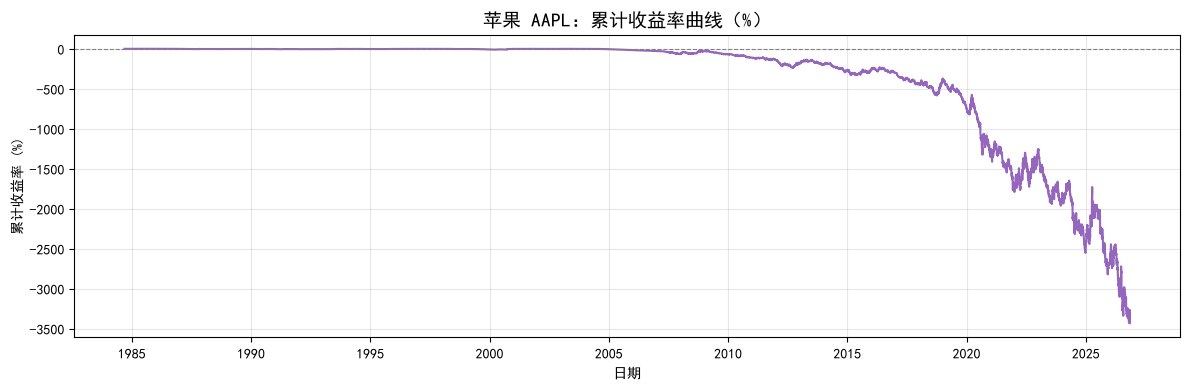

这段区间累计涨跌: -3433.33%


In [9]:
# ========== 累计收益率曲线 ==========
cum_return = (1 + rets).cumprod() - 1  # 每天 (1+r) 连乘，再减1得到累计涨跌

plt.figure(figsize=(12, 4))  # 创建画布
plt.plot(cum_return.index, cum_return.values * 100, color='tab:purple', linewidth=1.5)  # 画折线图
plt.axhline(0, color='gray', linestyle='--', linewidth=0.8)  # 画水平参考线
plt.title('苹果 AAPL：累计收益率曲线（%）', fontsize=14)  # 设置图标题
plt.xlabel('日期')  # 设置横轴标签
plt.ylabel('累计收益率 (%)')  # 设置纵轴标签
plt.grid(True, alpha=0.3)  # 显示网格线
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片

print(f'这段区间累计涨跌: {cum_return.iloc[-1]:.2%}')  # 打印价格统计


---

### 2.5 小实验：谁波动更大？

同样是科技股，**苹果 AAPL**、**特斯拉 TSLA**、**英伟达 NVDA** 的「脾气」一样吗？

我们用 **日收益率的标准差** 衡量波动（标准差越大，涨跌越猛）。这是你在量化路上的第一个 **对比实验**——欢迎改参数、换股票！

In [10]:
# ========== 小实验：下载三只股票并算波动 ==========
tickers = {  # 要对比的股票列表
    'AAPL': '苹果',  # 字典字段
    'TSLA': '特斯拉',  # 字典字段
    'NVDA': '英伟达',  # 字典字段
}  # 执行本行代码

period = '1y'   # 时间长度，可改成 '6mo'、'2y'
all_rets = {}   # 用字典存每只股票的中文名 → 日收益率序列

for symbol, name in tickers.items():  # 逐只股票下载
    # 从本地 AkShare 原始响应缓存取真实日线，避免重复请求和 Yahoo 限流
    data = pd.read_csv(f'../../data/akshare_us/{symbol}.csv', parse_dates=['date']).set_index('date')
    data = data.rename(columns={'open':'Open','high':'High','low':'Low','close':'Close','volume':'Volume'}).dropna()
    all_rets[name] = data['Close'].pct_change().dropna()  # 只关心收盘价涨跌
    print(f'{name} ({symbol}): {len(all_rets[name])} 个交易日')  # 打印统计结果

vol = pd.Series({name: s.std() for name, s in all_rets.items()}).sort_values(ascending=False)  # 求标准差（波动大小）
print('\n=== 日收益率波动（标准差，越大越猛）===')  # 打印分隔线或结论
for name, v in vol.items():  # 代码块开始
    print(f'  {name}: {v:.3%}')  # 格式化打印


苹果 (AAPL): 10067 个交易日
特斯拉 (TSLA): 3938 个交易日
英伟达 (NVDA): 5799 个交易日

=== 日收益率波动（标准差，越大越猛）===
  英伟达: 148.854%
  苹果: 7.055%
  特斯拉: 3.576%


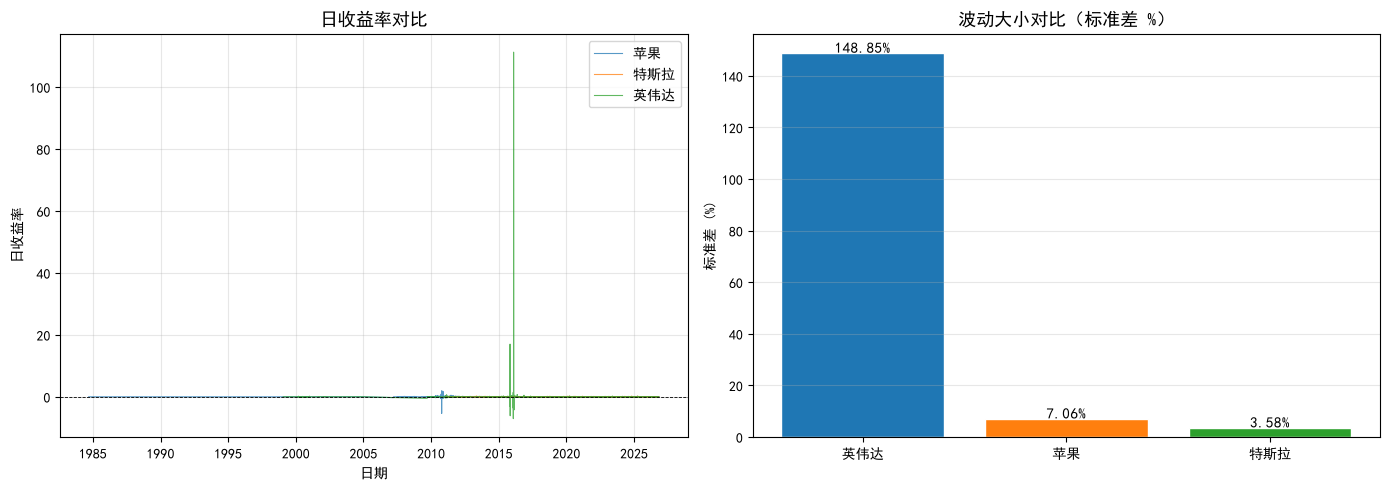


在本实验设定下（1y 日线），波动最大的是：英伟达


In [11]:
# ========== 三只股票收益率对比图 ==========
fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # 创建子图
colors = ['tab:blue', 'tab:orange', 'tab:green']  # 各曲线颜色

for (name, series), c in zip(all_rets.items(), colors):  # 逐只股票画曲线
    axes[0].plot(series.index, series.values, label=name, alpha=0.75, linewidth=0.8)  # 上图：画折线
axes[0].axhline(0, color='black', linestyle='--', linewidth=0.6)  # 上图画参考线
axes[0].set_title('日收益率对比', fontsize=13)  # 设置上图标题
axes[0].set_xlabel('日期')  # 执行本行代码
axes[0].set_ylabel('日收益率')  # 设置上图纵轴
axes[0].legend()  # 显示上图图例
axes[0].grid(True, alpha=0.3)  # 上图显示网格

axes[1].bar(vol.index, vol.values * 100, color=colors[: len(vol)], edgecolor='white')  # 下图：画柱状图
axes[1].set_title('波动大小对比（标准差 %）', fontsize=13)  # 设置下图标题
axes[1].set_ylabel('标准差 (%)')  # 设置下图纵轴
axes[1].grid(True, axis='y', alpha=0.3)  # 下图显示网格
for i, v in enumerate(vol.values):  # 在柱顶标注数值
    axes[1].text(i, v * 100 + 0.02, f'{v:.2%}', ha='center', fontsize=11)  # 字号

plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片

winner = vol.index[0]  # 波动最大的股票
print(f'\n在本实验设定下（{period} 日线），波动最大的是：{winner}')  # 格式化打印


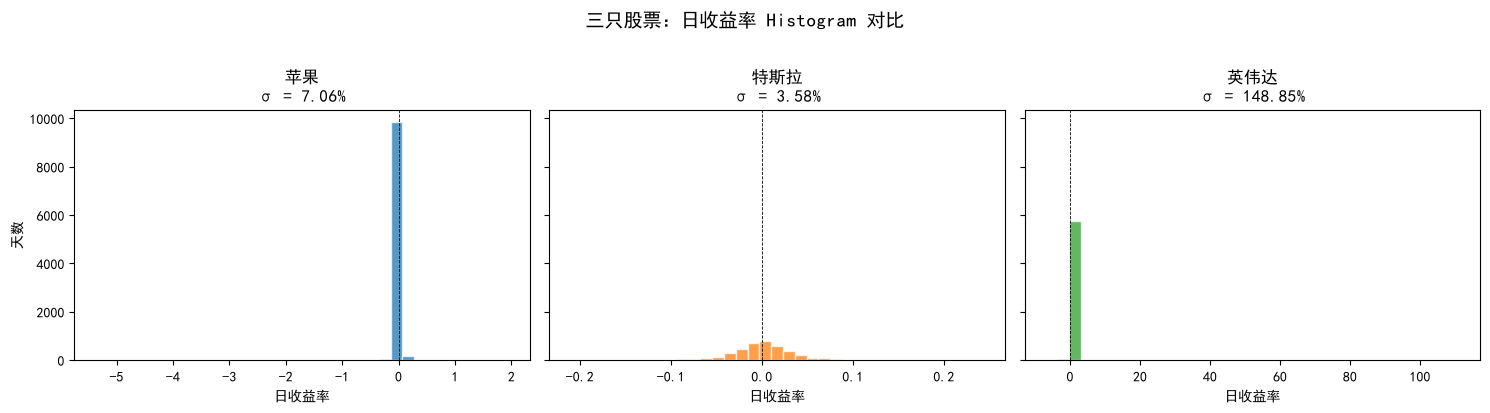

In [12]:
# ========== 三只股票 Histogram 并排对比 ==========
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)  # 创建子图

for ax, (name, series), c in zip(axes, all_rets.items(), colors):  # 逐只股票画直方图
    ax.hist(series.values, bins=35, color=c, alpha=0.75, edgecolor='white')  # 透明度
    ax.axvline(0, color='black', linestyle='--', linewidth=0.6)  # 画垂直参考线
    ax.set_title(f'{name}\nσ = {series.std():.2%}')  # 求标准差（波动大小）
    ax.set_xlabel('日收益率')  # 设置子图横轴

axes[0].set_ylabel('天数')  # 设置上图纵轴
fig.suptitle('三只股票：日收益率 Histogram 对比', fontsize=14, y=1.02)  # 整张图的总标题
plt.tight_layout()                       # 自动调整子图间距，避免标签被裁切
plt.show()                               # 在 Notebook 里显示图片


---

## 🎯 挑战任务（第二章通关）

1. **三选一**：把实验里的 `'AAPL'`、`'TSLA'`、`'NVDA'` 换成你最喜欢的一家公司，重做 **波动对比** 小实验。  
2. **截图打卡**：保存一张「收益率 Histogram」图，发好友或学习群。  
3. **思考题**：Histogram 尾巴很长，说明这类股票可能有什么特点？


## 本章总结

- **OHLCV** 是日线数据的标准五官；做量化时 **Close** 最常用。  
- **收益率** 描述的是「相对昨天涨了多少比例」；先理解 100→110 的 10%，再记公式。  
- `pct_change()` = 日收益率；配合 **曲线 + 直方图**，就有了金融数据分析的初体验。  
- **标准差** 可以粗略比较谁波动更大——苹果、特斯拉、英伟达，往往不是一个脾气。

**下一章预告**：我们会用 **移动平均线** 把价格「磨平滑」，并尝试你的第一个简单交易规则。